In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from src.research.qcut_analyzer import QcutAnalyzer
# QcutAnalyzer.plot_qcut_analysis(df, col_a='Factor_A', col_b='Return')
%load_ext autoreload
%autoreload 2
from sdk_core import configure
from sdk_core import TwMarketData
# configure()
from src.research.rolling_model import train_and_predict_ridge_rolling

tw = TwMarketData()
# 取得還原股價
df = tw.get_security_price_adjusted("2025-12-31", "2330")

import os
import numpy as np
from tqdm import tqdm
import time
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
# 將最大顯示欄位數量設為 None（代表無上限）
pd.set_option('display.max_columns', None)

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))

import pyarrow as pa
schema = pa.schema([
    ('price', pa.decimal128(10, 4)), 
    # 其他欄位如果沒特別指定，pyarrow 會自動推斷
])

from src.research.backTest import BackTest


In [2]:

folder_path = './data'  # 資料夾路徑
files = os.listdir(folder_path)

# 過濾掉資料夾，只留下檔案
file_names = np.array([f for f in files if os.path.isfile(os.path.join(folder_path, f))])
file_names.sort()
print(file_names[-30:])

['20260717.parquet' '20260720.parquet' '20260721.parquet'
 '20260722.parquet' '20260723.parquet' '20260724.parquet'
 '20260727.parquet' '20260728.parquet' '20260729.parquet'
 '20260730.parquet' '20260731.parquet' '20260803.parquet'
 '20260804.parquet' '20260805.parquet' '20260806.parquet'
 '20260807.parquet' '20260810.parquet' '20260811.parquet'
 '20260812.parquet' '20260813.parquet' '20260814.parquet'
 '20260817.parquet' '20260818.parquet' '20260819.parquet'
 '20260820.parquet' '20260821.parquet' '20260824.parquet'
 '20260825.parquet' '20260826.parquet' '20260827.parquet']


In [3]:
data = []

# 範例：處理 100 個檔案
for f in tqdm (file_names[-230:]): 
    targetLabel = 'BidPrice1' 
    rankThres_btn = 0 
    rankThres = 150
    stock_df = pd.read_parquet( f'{folder_path}/{f}' )[lambda x : x[targetLabel] * x.BidPrice1 > 0]
    try : 
        stock_df['ToRef'] = ((stock_df['BidPrice1'] - stock_df.RefPrice) / stock_df.RefPrice ).round(6)
        stock_df['ToOpen'] = ((stock_df['BidPrice1'] - stock_df.Open) / stock_df.Open ).round(6)
        # stock_df['TakerSell_CloseBP'] = ((stock_df[targetLabel]- stock_df.Close) / stock_df[targetLabel] * 10000)
        # stock_df.loc[ stock_df.FutureHigh > stock_df.RefPrice*1.09 , 'TakerSell_CloseBP'] = ((stock_df[targetLabel] - stock_df.FutureHigh) / stock_df[targetLabel] * 10000)
        stock_df['TakerSell_CloseBP'] = ((stock_df[targetLabel]- stock_df.Close) / stock_df[targetLabel] * 10000)
        stock_df.loc[ stock_df.FutureHigh > stock_df.RefPrice*1.08 , 'TakerSell_CloseBP'] = ((stock_df[targetLabel] - stock_df.RefPrice*1.08 - stock_df.TickSize*2) / stock_df[targetLabel] * 10000)
        PriceCondition = (stock_df.ToRef > -0.015) & (stock_df.ToRef < 0.05)
        # seqCondition = (stock_df.BidPrice1.diff()!= 0)
        AmountCondition = (stock_df.day_amount_rank <= rankThres) | (stock_df.AmountRank_canDayTrade <= rankThres) 
        # AmountCondition2 = (stock_df.day_amount_rank > rankThres_btn) & (stock_df.AmountRank > rankThres_btn)
        # preMarketCondition = (stock_df.day_amount_rank <= 50.1) | (stock_df.AmountRank <= 50.1)
        temp = stock_df[ PriceCondition & AmountCondition].reset_index(drop=True)
        temp['Date'] = f.split('.')[0]
        data.append(temp)
    except : 
        print('Filled in ', f)
        continue
        # break       
    # if f.split('.')[0] == '20260309':
    #     break

100%|██████████| 230/230 [01:04<00:00,  3.59it/s]


In [4]:
import gc

if 'signal_df' in locals():
    del signal_df
    gc.collect()

signal_df = pd.concat(data, ignore_index=True, copy=False)

priceReturnColumn = ["TransTime", "QuoteCode", "ChannelSeq","TotalFillLots","BidPrice1","BidLots1", "AskPrice1","AskLots1", "RecordHigh","FutureHigh", "RefPrice" , "Close" , "Open", "Spread", "TakerSell_CloseBP" ]
signal_df[priceReturnColumn + ['ToRef','FillLots_atLow','day_amount_rank', 'AmountRank', 'TimeSlot','TransTime_tb']].head(10)


/tmp/ipykernel_3356948/2134462285.py:7: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  signal_df = pd.concat(data, ignore_index=True, copy=False)


,TransTime,QuoteCode,ChannelSeq,TotalFillLots,BidPrice1,BidLots1,AskPrice1,AskLots1,RecordHigh,FutureHigh,RefPrice,Close,Open,Spread,TakerSell_CloseBP,ToRef,FillLots_atLow,day_amount_rank,AmountRank,TimeSlot,TransTime_tb
0,2025-09-15 09:09:21.235097,1303,900461,2163,37.75,109,37.85,116,37.95,37.9,37.65,37.5,37.8,2.0,66.225166,0.002656,-22,153.0,137.0,09:05:00,2025-09-15 09:04:59.311415
1,2025-09-15 09:09:56.592726,1303,946798,2501,37.60,21,37.70,95,37.95,37.9,37.65,37.5,37.8,2.0,26.595745,-0.001328,-270,153.0,137.0,09:05:00,2025-09-15 09:04:59.311415
2,2025-09-15 09:10:07.638545,1303,961894,2507,37.65,1,37.70,95,37.95,37.9,37.65,37.5,37.8,1.0,39.840637,0.000000,-264,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
3,2025-09-15 09:10:08.425303,1303,963487,2510,37.60,64,37.70,95,37.95,37.9,37.65,37.5,37.8,2.0,26.595745,-0.001328,-267,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
4,2025-09-15 09:10:09.090677,1303,964451,2511,37.65,1,37.70,95,37.95,37.9,37.65,37.5,37.8,1.0,39.840637,0.000000,-266,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
5,2025-09-15 09:10:11.507944,1303,968724,2606,37.70,3,37.75,78,37.95,37.9,37.65,37.5,37.8,1.0,53.050398,0.001328,-171,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
6,2025-09-15 09:10:13.678900,1303,974038,2684,37.75,8,37.80,230,37.95,37.9,37.65,37.5,37.8,1.0,66.225166,0.002656,-93,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
7,2025-09-15 09:12:30.683159,1303,1150688,3513,37.55,72,37.65,345,37.95,37.9,37.65,37.5,37.8,2.0,13.315579,-0.002656,-20,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
8,2025-09-15 09:12:39.721116,1303,1161591,3524,37.60,2,37.70,10,37.95,37.9,37.65,37.5,37.8,2.0,26.595745,-0.001328,-13,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521
9,2025-09-15 09:12:41.009322,1303,1163208,3526,37.65,6,37.75,21,37.95,37.9,37.65,37.5,37.8,2.0,39.840637,0.000000,-15,153.0,144.0,09:10:00,2025-09-15 09:09:58.740521


In [5]:
signal_df['residual_TakerSell_CloseBP'] = (
    signal_df.TakerSell_CloseBP
    + signal_df.txf_beta_60d * signal_df.txf_to_1330_bp        # BP，單位已對齊
) / (signal_df.txf_residual_vol_to_1330 * 1e4)      

In [6]:
signal_df = signal_df[ (signal_df.TransTime.dt.time < datetime.time(12, 30, 0)) & (signal_df.TransTime.dt.time > datetime.time(9, 0, 30)) & (signal_df.TrialMatch == 0) ].reset_index(drop=True)
signal_df = signal_df[  (signal_df.TakerSell_CloseBP.abs() < 10000) ].sort_values(['Date', 'QuoteCode', 'TransTime']).reset_index(drop=True)
signal_df['midEdge_300sBP'] = signal_df['midEdge_300sBP']*-1

<Axes: xlabel='Date'>

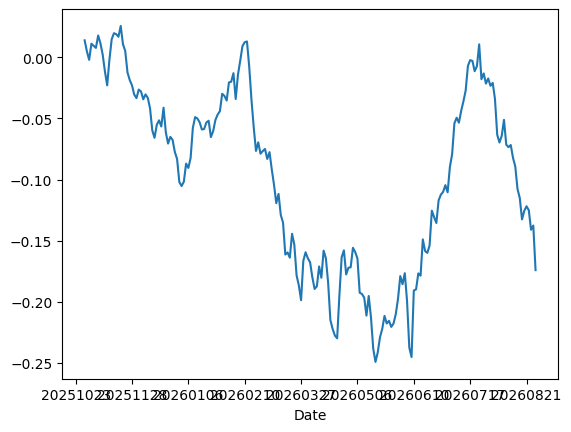

In [7]:
signal_df[:].groupby(['Date','QuoteCode']).residual_TakerSell_CloseBP.mean().reset_index().groupby(['Date']).residual_TakerSell_CloseBP.mean().rolling(30).mean().plot()

In [8]:
signal_df['TakerSell_CloseBP_net'] = signal_df.residual_TakerSell_CloseBP.copy() - signal_df.groupby(['Date','QuoteCode']).residual_TakerSell_CloseBP.transform('mean') #- (signal_df.FutureHigh > signal_df.RefPrice *1.08) * 20#.clip(lower=-130, upper=130)
signal_df['TakerSell_CloseBP_netM'] = signal_df.residual_TakerSell_CloseBP - signal_df.groupby(['Date']).residual_TakerSell_CloseBP.transform('mean') #.clip(lower=-130, upper=130)
# signal_df['TakerSell_CloseBP_net'] = signal_df.TakerSell_CloseBP - signal_df.groupby(['Date','QuoteCode']).TakerSell_CloseBP.transform('mean')#.clip(lower=-130, upper=130)
# signal_df['TakerSell_CloseBP_net'] = signal_df.TakerSell_CloseBP - signal_df.groupby(['Date']).TakerSell_CloseBP.transform('mean')

<Axes: xlabel='Date'>

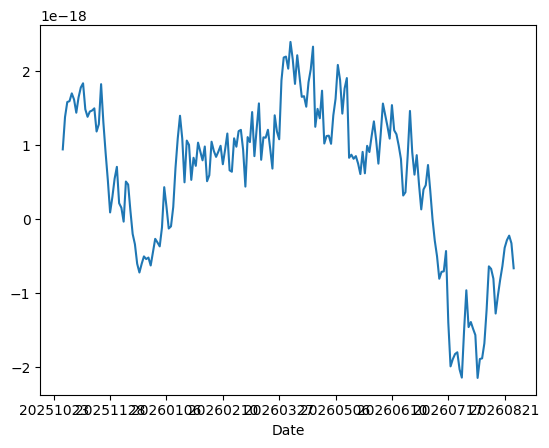

In [9]:
signal_df[:].groupby(['Date','QuoteCode']).TakerSell_CloseBP_net.mean().reset_index().groupby(['Date']).TakerSell_CloseBP_net.mean().rolling(30).mean().plot()

In [10]:
import pandas as pd
import json

# 1. 讀取 JSON 檔案還原成 list
with open('abnormal_dates.json', 'r') as f:
    loaded_date_list = json.load(f)

signal_df['isAbnormalDate'] = (signal_df['Date'].astype(str).isin(loaded_date_list) ) *1 
# signal_df.loc[ signal_df.Date == signal_df.Date.max(), 'isAbnormalDate'] = 1


In [11]:
signal_df['isAbnormalDate'].unique()

array([0, 1])

In [12]:
signal_df['B2_Last'] = signal_df.BidLots2 / signal_df.avg_bidLots1
signal_df['A2_Last'] = signal_df.AskLots2 / signal_df.avg_askLots1

signal_df['B1_B12'] = signal_df.BidLots1 / (signal_df.BidLots1+signal_df.BidLots2)
signal_df['A1_A12'] = signal_df.AskLots1 / (signal_df.AskLots1+signal_df.AskLots2)
signal_df['B45_AB45'] = (signal_df.BidLots4 + signal_df.BidLots5 ) / (signal_df.AskLots4 + signal_df.AskLots5 + signal_df.BidLots4 + signal_df.BidLots5 )

signal_df['Total_Last'] = signal_df.TotalFillLots / signal_df.last_fillLots
signal_df['TickBP'] = signal_df.TickSize / signal_df.BidPrice1 * 10000
signal_df['LOB_BidVelocity_30_re'] = signal_df.LOB_BidVelocity_30.abs() / signal_df.avg_bidLots1
signal_df['LOB_AskVelocity_30_re'] = signal_df.LOB_AskVelocity_30.abs() / signal_df.avg_askLots1

signal_df['FillLots_atLow_re'] = signal_df.FillLots_atLow / (signal_df.avg_bidLots1 + signal_df.avg_askLots1)
signal_df['FillLots_atHigh_re'] = signal_df.FillLots_atHigh / (signal_df.avg_bidLots1 + signal_df.avg_askLots1)

signal_df['L1_SellBiggestLots_30_re'] = signal_df.L1_SellBiggestLots_30.abs() / signal_df.big_sell_lots
signal_df['L1_BuyBiggestLots_30_re'] = signal_df.L1_BuyBiggestLots_30.abs() / signal_df.big_buy_lots

signal_df['MD_ElaspeTime_30_re'] = (signal_df.MD_ElaspeTime_30+1).apply(np.log)
signal_df['MD_L1Rate_30_re'] = signal_df.MD_L1Rate_30

signal_df['IA_BuyImpact_30_re'] = (signal_df.IA_BuyImpact_30.abs()+1).apply(np.log)
signal_df['IA_SellImpact_30_re'] = (signal_df.IA_SellImpact_30.abs()+1).apply(np.log)
signal_df['LOB_NetPressure_30_re'] = (signal_df.LOB_NetPressure_30.abs()+1).apply(np.log)
signal_df['QL_Asymmetry_re'] = (signal_df.QL_Asymmetry.abs()+1).apply(np.log)


/tmp/ipykernel_3356948/489644927.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  signal_df['IA_SellImpact_30_re'] = (signal_df.IA_SellImpact_30.abs()+1).apply(np.log)
/tmp/ipykernel_3356948/489644927.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  signal_df['LOB_NetPressure_30_re'] = (signal_df.LOB_NetPressure_30.abs()+1).apply(np.log)
/tmp/ipykernel_3356948/489644927.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance. 

In [13]:
based_columns = ['QuoteCode', 'ChannelSeq', 'InOut', 'Overshoot', 'TotalFillLots', 'BidPrice1','BidLots1', 'BidLots5', 'AskPrice1', 'AskLots1', 'AskLots5', 'FillLots']
feature_columns = ['ToLow', 'ToHigh', 'Low_High', 'TickSize', 'TickBP', 'ToRef', 'ToOpen', 'B1_A1B1', 'B1_B1B5', 'B12_B1B5', 'A1_A1A5', 'A12_A1A5', 'Spread', 'RemainSeconds']#'B1_Last','Total_Last']
cross_columns = ['AmountRank', 'netAmountRank', 'TotalFillLotsRank', 'netTotalFillLotsRank', 'ToRefRank']
day_columns = ['dealer_hedging_netLots', 'dealer_netLots', 'foreign_dealer_netLots', 'foreign_netLots', 'investment_netLots', 'margin_netLots', 'short_netLots', 'nextday_allow_day_trade_mark', 'trading_volume_noOdd', 'big_buy_lots', 'big_buy_ToCloseBP', 'big_buy_300sBP', 'big_sell_lots', 'big_sell_ToCloseBP', 'big_sell_300sBP', 'hft_participation', 'hft_buy_ToCloseBP', 'hft_buy_300sBP', 'hft_sell_ToCloseBP', 'hft_sell_300sBP', 'day_amount_rank', 'day_lots_rank']
# # 
feature = based_columns + feature_columns + cross_columns + day_columns
label = 'TakerSell_CloseBP_net'
# feature_columns = ['ToLow', 'ToHigh', 'Low_High',  'RemainSeconds',  'ToOpen', 'ToRef',
#   'B1_A1B1', 'B1_B1B5', 'A1_A1A5', 'B2_Last', 'A2_Last', 'B45_AB45','B1_B12','A1_A12', 'QL_BidHHI', 'QL_AskHHI'] + signal_df.columns[ (signal_df.columns.str.contains('_re')) & ~(signal_df.columns.str.contains('2330')) & ~(signal_df.columns.str.startswith('txf_')) ].tolist() + ['txf_residual_vol_to_1330', 'txf_residual_vol_0900_1330_60d']
# txf_to_1330_return 是事件→13:30 的期貨「未來」報酬，_re regex 會掃到它，絕不可進特徵
feature_columns = ['ToLow', 'ToHigh', 'Low_High', 'ToRef', 'ToOpen', 'B1_A1B1','B1_B1B5', 'A1_A1A5', 'B45_AB45','B1_B12','A1_A12', 'RemainSeconds', 'MD_ElaspeTime_30_re','MD_L1Rate_30']#, 'txf_residual_vol_to_1330', 'txf_residual_vol_0900_1330_60d'] # + signal_df.columns[ (signal_df.columns.str.contains('_re')) & ~(signal_df.columns.str.contains('2330')) ].tolist()
# day_columns = ['foreign_netLots', 'investment_netLots','margin_netLots','turnover_rate','hft_strick_makerSpreadBP','hft_strick_participation','hft_participation','big_sell_ToCloseBP']

In [14]:
for c in feature_columns : 
    signal_df[c] = signal_df[c].round(6)
signal_df ['OTC'] = signal_df ['OTC'] * 1

🔍 目前預測目標: TakerSell_CloseBP_net | Rolling Training 視窗: 60 天
🔄 為了 O(1) NumPy 加速，強制將資料依照 Date, QuoteCode, TransTime 進行排序...
📊 資料總筆數: 6566966
🔄 填補特徵遺失值 (依據前一交易日之中位數)...
----------------------------------------
🚀 總輸入 current_X (共 14 個)
   - Tick Baseline: 14 個
   - Day Features:  0 個
   - Forced Masks:  0 個
----------------------------------------
🔄 計算 Lot Mask 與準備 NumPy 陣列
🔬 Phase 1: 預先計算 Feature Screening (worker: 16)...


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   9 tasks      | elapsed:    0.3s
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=16)]: Done  29 tasks      | elapsed:    1.0s
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    1.6s
[Parallel(n_jobs=16)]: Done  53 tasks      | elapsed:    2.6s
[Parallel(n_jobs=16)]: Done  66 tasks      | elapsed:    3.7s
[Parallel(n_jobs=16)]: Done  81 tasks      | elapsed:    5.1s
[Parallel(n_jobs=16)]: Done  96 tasks      | elapsed:    6.2s
[Parallel(n_jobs=16)]: Done 113 tasks      | elapsed:    7.7s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    9.8s
[Parallel(n_jobs=16)]: Done 149 tasks      | elapsed:   11.6s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:   13.8s
[Parallel(n_jobs=16)]: Done 189 tasks      | elapsed:   16.5s
[Parallel(n_jobs=16)]: Done 223 out of 230 | elapsed:   20.7s remaining:    0.7s
[Parallel(n_jobs=16)]: Done 230

✅ Phase 1 完成！
▶️ Phase 2: Rolling Update (Core: -1)...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:    1.7s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    3.1s
[Parallel(n_jobs=-1)]: Done  49 tasks      | elapsed:    5.7s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    8.0s
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:   11.0s
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:   13.4s
[Parallel(n_jobs=-1)]: Done 117 tasks      | elapsed:   17.3s
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:   20.2s
[Parallel(n_jobs=-1)]: Done 157 tasks      | elapsed:   24.7s
[Parallel(n_jobs=-1)]: Done 191 out of 230 | elapsed:   32.1s remaining:    6.6s
[Parallel(n_jobs=-1)]: Done 215 out of 230 | elapsed:   36.1s remaining:    2.5s
[Parallel(n_jobs=-1)]: Done 230 out of 230 | elapsed:   37.2s finished


✅ 平行 Rolling 更新預測完成！
  Rolling Model Dashboard — NORMAL Model
  交易日數: 229  |  特徵數: 14
  Feature Screening: OFF (所有天都使用全部特徵)

📊 [1/2] Standardized Coefficient Importance


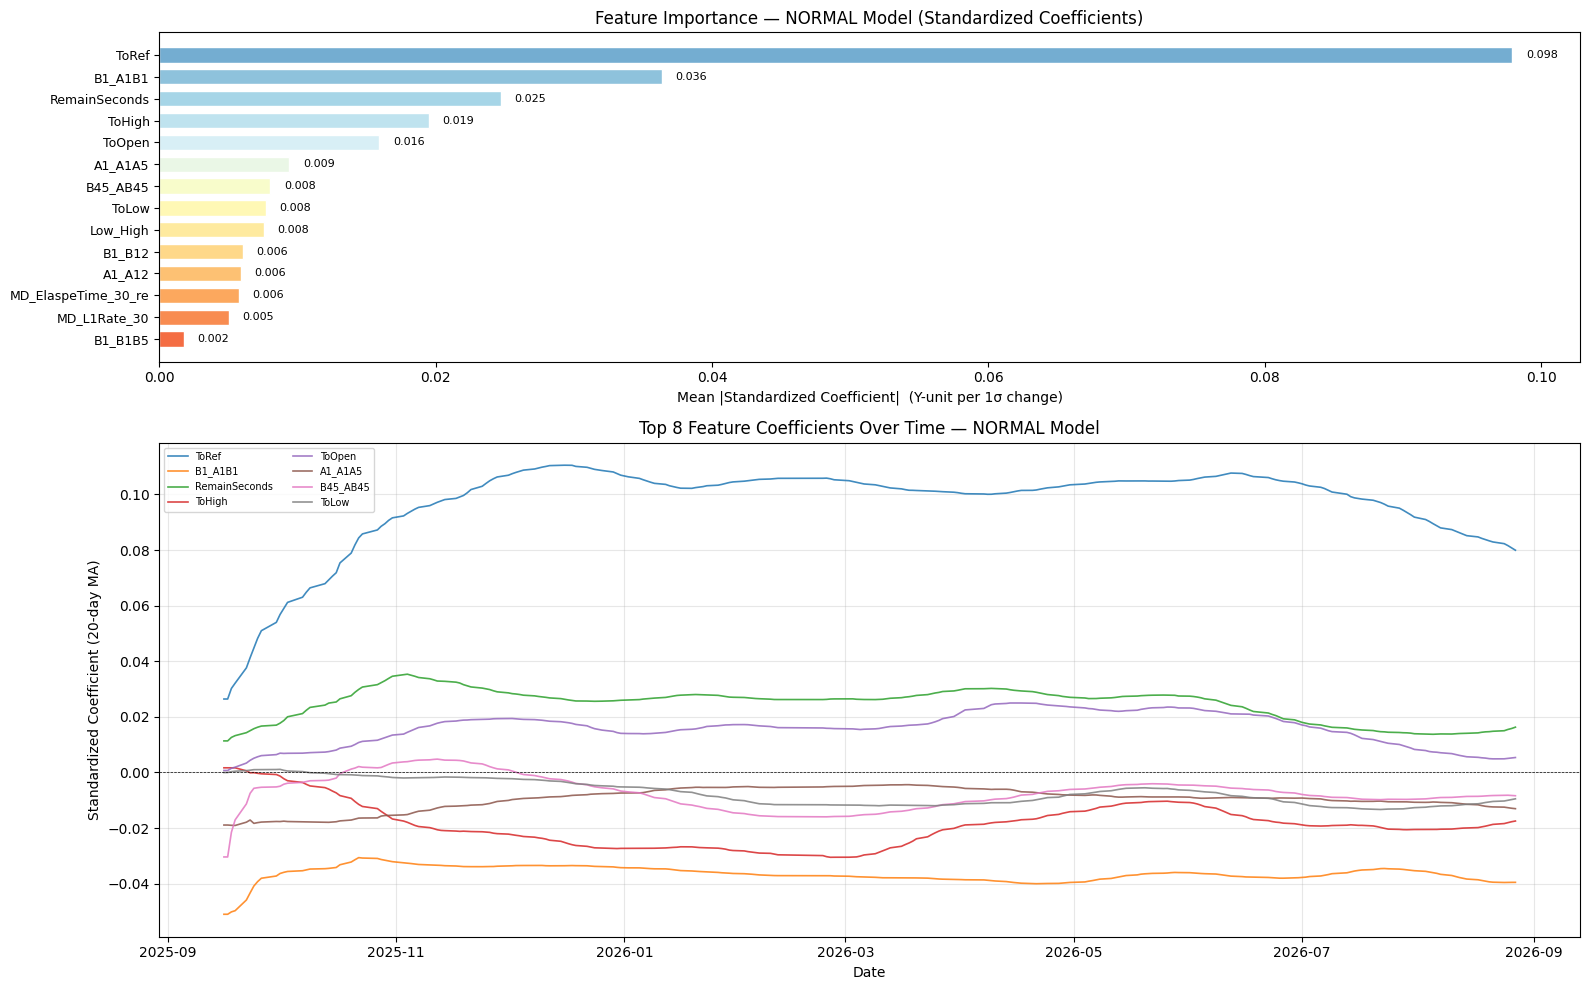


📊 [2/2] Coefficient Stability


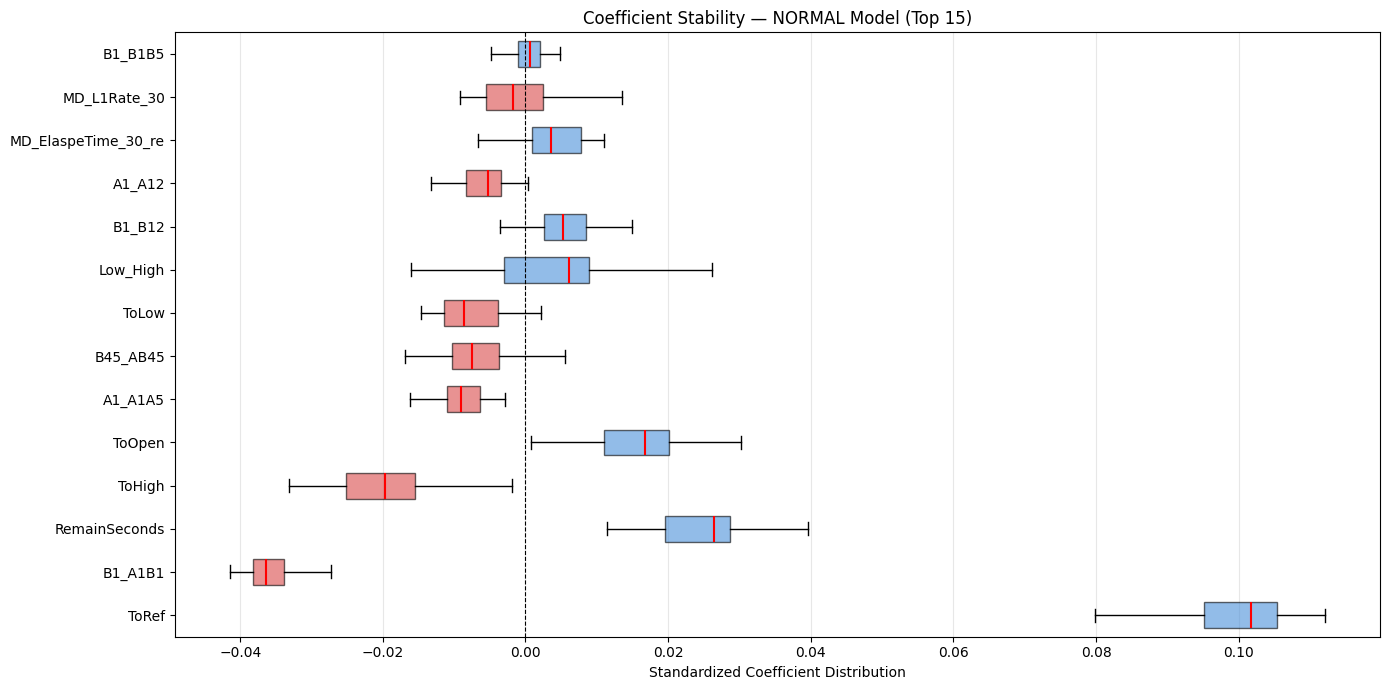

🔍 目前預測目標: TakerSell_CloseBP_netM | Rolling Training 視窗: 20 天
🔄 為了 O(1) NumPy 加速，強制將資料依照 Date, QuoteCode, TransTime 進行排序...
📊 資料總筆數: 6559931
🔄 填補特徵遺失值 (依據前一交易日之中位數)...
----------------------------------------
🚀 總輸入 current_X (共 14 個)
   - Tick Baseline: 14 個
   - Day Features:  0 個
   - Forced Masks:  0 個
----------------------------------------
🔄 計算 Lot Mask 與準備 NumPy 陣列
🔬 Phase 1: 預先計算 Feature Screening (worker: 16)...


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   9 tasks      | elapsed:    0.3s
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.4s
[Parallel(n_jobs=16)]: Done  29 tasks      | elapsed:    0.8s
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    1.1s
[Parallel(n_jobs=16)]: Done  53 tasks      | elapsed:    1.4s
[Parallel(n_jobs=16)]: Done  66 tasks      | elapsed:    1.7s
[Parallel(n_jobs=16)]: Done  81 tasks      | elapsed:    2.1s
[Parallel(n_jobs=16)]: Done  96 tasks      | elapsed:    2.6s
[Parallel(n_jobs=16)]: Done 113 tasks      | elapsed:    3.1s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    3.7s
[Parallel(n_jobs=16)]: Done 149 tasks      | elapsed:    4.3s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    5.2s
[Parallel(n_jobs=16)]: Done 189 tasks      | elapsed:    6.1s
[Parallel(n_jobs=16)]: Done 223 out of 230 | elapsed:    7.3s remaining:    0.2s
[Parallel(n_jobs=16)]: Done 230

✅ Phase 1 完成！
▶️ Phase 2: Rolling Update (Core: -1)...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:    1.5s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    2.1s
[Parallel(n_jobs=-1)]: Done  49 tasks      | elapsed:    3.6s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    4.5s
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:    5.9s
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:    7.0s
[Parallel(n_jobs=-1)]: Done 117 tasks      | elapsed:    8.8s
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:   10.5s
[Parallel(n_jobs=-1)]: Done 157 tasks      | elapsed:   12.5s
[Parallel(n_jobs=-1)]: Done 191 out of 230 | elapsed:   15.9s remaining:    3.3s
[Parallel(n_jobs=-1)]: Done 215 out of 230 | elapsed:   17.6s remaining:    1.2s
[Parallel(n_jobs=-1)]: Done 230 out of 230 | elapsed:   17.9s finished


✅ 平行 Rolling 更新預測完成！
  Rolling Model Dashboard — NORMAL Model
  交易日數: 229  |  特徵數: 14
  Feature Screening: OFF (所有天都使用全部特徵)

📊 [1/2] Standardized Coefficient Importance


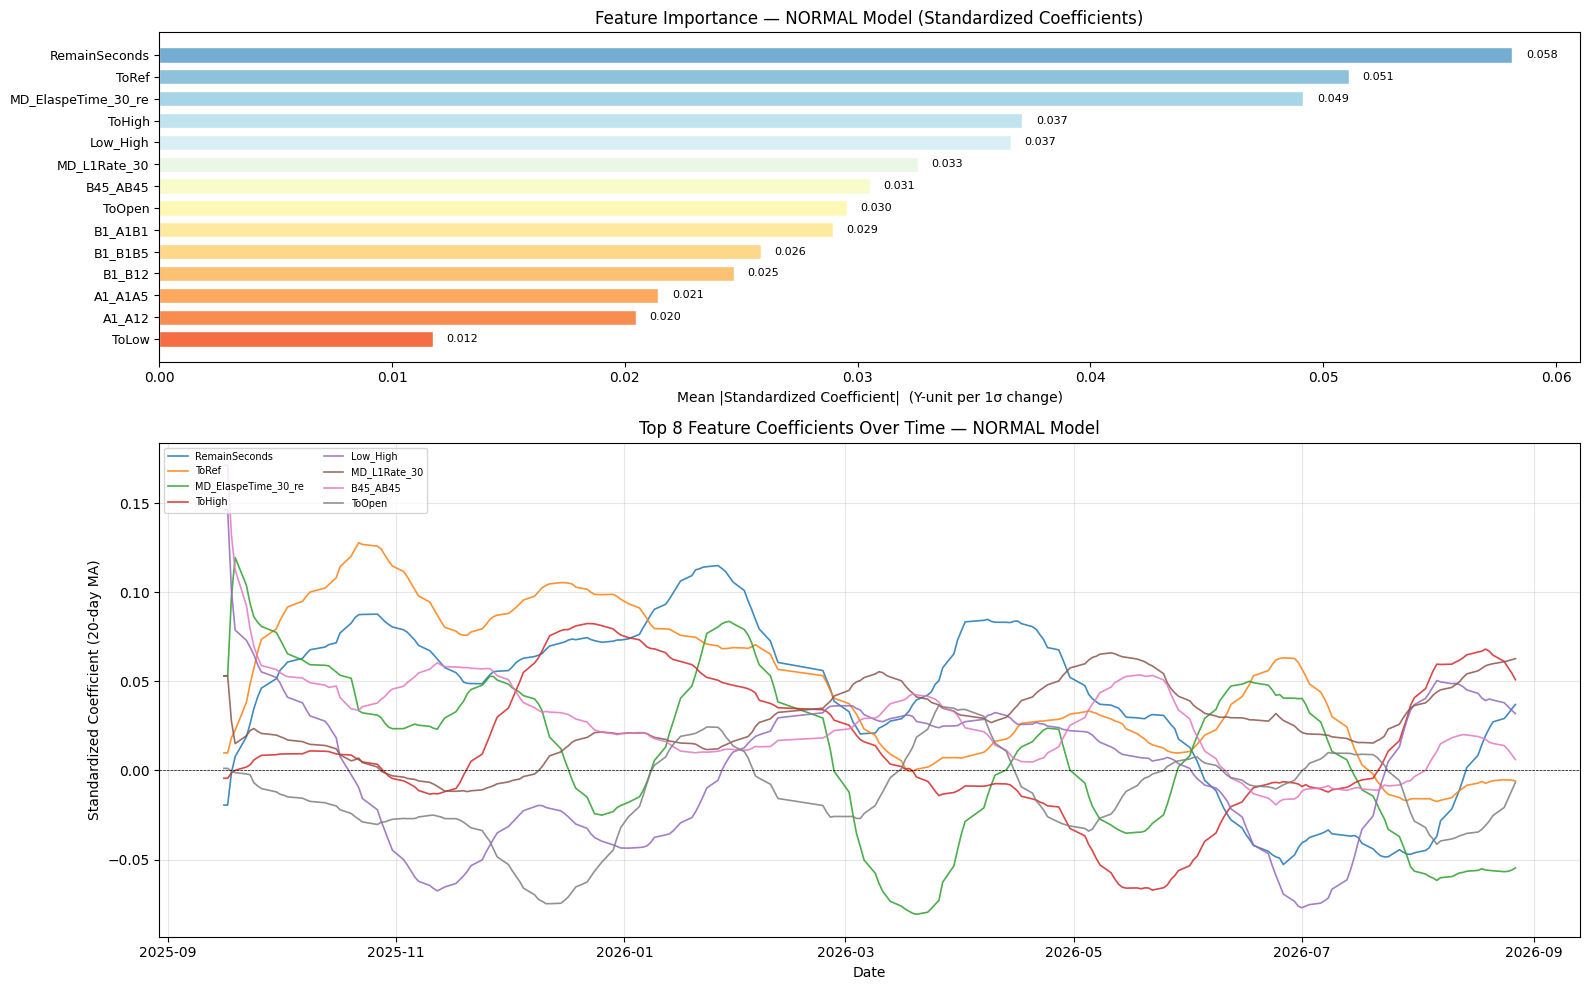


📊 [2/2] Coefficient Stability


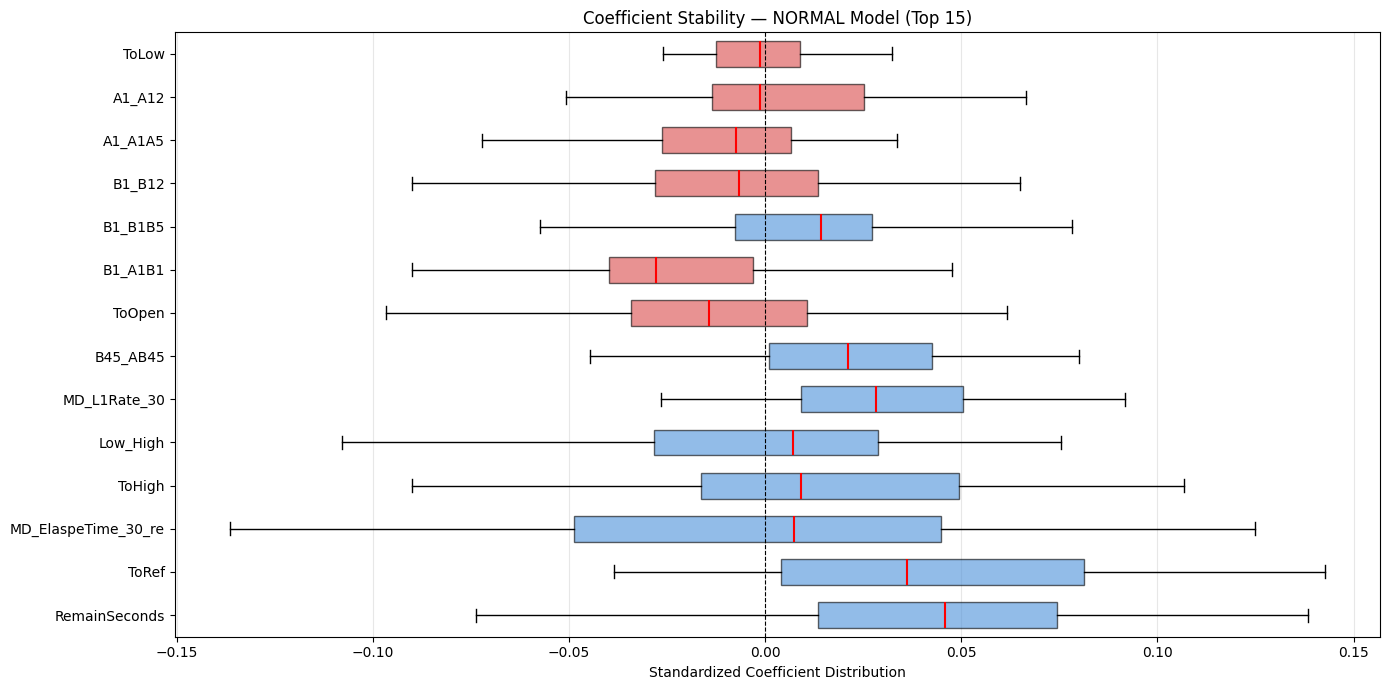

In [15]:
day_columns = []
from src.research.timeSeries.model_analysis import plot_model_dashboard

# result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label,  n_training_days=20,  day_features= day_columns, feature_screening=True, alpha=0.1 , max_position_per_stock = 500)
result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label,  n_training_days=60,  day_features= day_columns, feature_screening=True, alpha=10 , max_position_per_stock = 500)
screening_log = result['screening_log']   # {日期: [被選中的特徵名]}
coeff_log = result['coeff_log']           # {日期: {normal_coeff, normal_std_coeff, ...}}day_features= day_columns, day_features= day_columns,
signal_df = result['df']           # 原本的 DataFrameㄌ
plot_model_dashboard(result, model_type='normal')

# day_columns = ['foreign_netLots', 'investment_netLots','margin_netLots','turnover_rate','hft_strick_makerSpreadBP','hft_strick_participation','hft_participation','big_sell_ToCloseBP']
result = train_and_predict_ridge_rolling(signal_df[:], feature_columns , label+'M', n_training_days=20,  day_features= day_columns, feature_screening=True, alpha=10 , max_position_per_stock = 500)
screening_log = result['screening_log']   # {日期: [被選中的特徵名]}
coeff_log2 = result['coeff_log']           # {日期: {normal_coeff, normal_std_coeff, ...}}
signal_df = result['df']
plot_model_dashboard(result, model_type='normal')


In [16]:
coeff_log

{'2025-09-16': {'selected_features': ['ToLow',
   'ToHigh',
   'Low_High',
   'ToRef',
   'ToOpen',
   'B1_A1B1',
   'B1_B1B5',
   'A1_A1A5',
   'B45_AB45',
   'B1_B12',
   'A1_A12',
   'RemainSeconds',
   'MD_ElaspeTime_30_re',
   'MD_L1Rate_30'],
  'normal_coeff': {'ToLow': -0.0005415151827037334,
   'ToHigh': 0.12962734699249268,
   'Low_High': -0.06479834765195847,
   'ToRef': 1.568144679069519,
   'ToOpen': 0.05795678496360779,
   'B1_A1B1': -0.17061373591423035,
   'B1_B1B5': -0.010654622688889503,
   'A1_A1A5': -0.1657126545906067,
   'B45_AB45': -0.14622898399829865,
   'B1_B12': 0.06856994330883026,
   'A1_A12': -0.1028781309723854,
   'RemainSeconds': 4.384750354802236e-06,
   'MD_ElaspeTime_30_re': -0.01500340923666954,
   'MD_L1Rate_30': 0.33178025484085083},
  'normal_std_coeff': {'ToLow': -4.841661393584218e-06,
   'ToHigh': 0.0016868559177964926,
   'Low_High': -0.016050048172473907,
   'ToRef': 0.02642514556646347,
   'ToOpen': 0.0007231220952235162,
   'B1_A1B1': -0.05

In [17]:
coeff_log2

{'2025-09-16': {'selected_features': ['ToLow',
   'ToHigh',
   'Low_High',
   'ToRef',
   'ToOpen',
   'B1_A1B1',
   'B1_B1B5',
   'A1_A1A5',
   'B45_AB45',
   'B1_B12',
   'A1_A12',
   'RemainSeconds',
   'MD_ElaspeTime_30_re',
   'MD_L1Rate_30'],
  'normal_coeff': {'ToLow': -0.067136749625206,
   'ToHigh': -0.33659037947654724,
   'Low_High': 0.5907602906227112,
   'ToRef': 0.5839571952819824,
   'ToOpen': 0.0931544303894043,
   'B1_A1B1': 0.15943998098373413,
   'B1_B1B5': -0.4455784559249878,
   'A1_A1A5': -0.07269681990146637,
   'B45_AB45': 0.8251187205314636,
   'B1_B12': -0.08531847596168518,
   'A1_A12': 0.09031727910041809,
   'RemainSeconds': -7.496378202631604e-06,
   'MD_ElaspeTime_30_re': 0.04969670996069908,
   'MD_L1Rate_30': 0.5347825884819031},
  'normal_std_coeff': {'ToLow': -0.0006002664449624717,
   'ToHigh': -0.004380090162158012,
   'Low_High': 0.14632673561573029,
   'ToRef': 0.009840388782322407,
   'ToOpen': 0.0011622803285717964,
   'B1_A1B1': 0.0476370789110

# z 單位的預測換回 BP 是「乘」vol（label 當初除以 vol），不是除
signal_df['TakerSell_CloseBP_netM_pred'] = signal_df['TakerSell_CloseBP_netM_pred'] * (signal_df.txf_residual_vol_to_1330 * 1e4)
signal_df['TakerSell_CloseBP_net_pred'] = signal_df['TakerSell_CloseBP_net_pred'] * (signal_df.txf_residual_vol_to_1330 * 1e4)

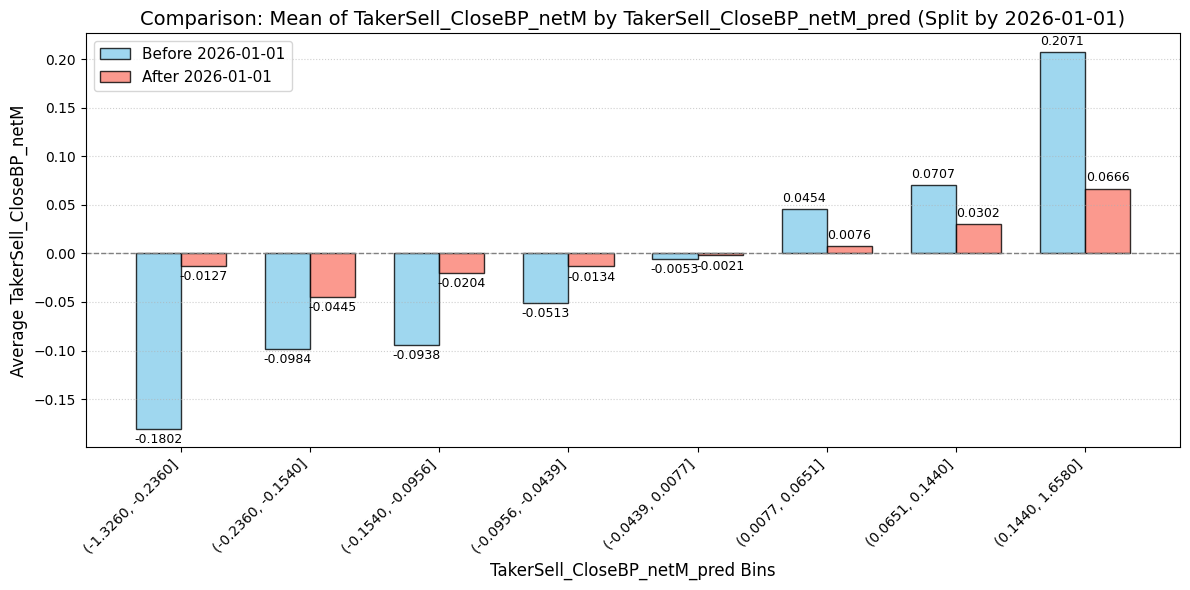

In [18]:
# 評估要對「對應 label」：pooled raw qcut 會把市場成分排進 bin（2026 反轉的來源）
QcutAnalyzer.plot_qcut_analysis(signal_df[signal_df.isAbnormalDate == 0], 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP_netM', date_col='Date', split_date='2026-01-01',  q= 8)
# 對照用（含市場成分）：
# QcutAnalyzer.plot_qcut_analysis(signal_df[signal_df.isAbnormalDate == 0], 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01',  q= 8)

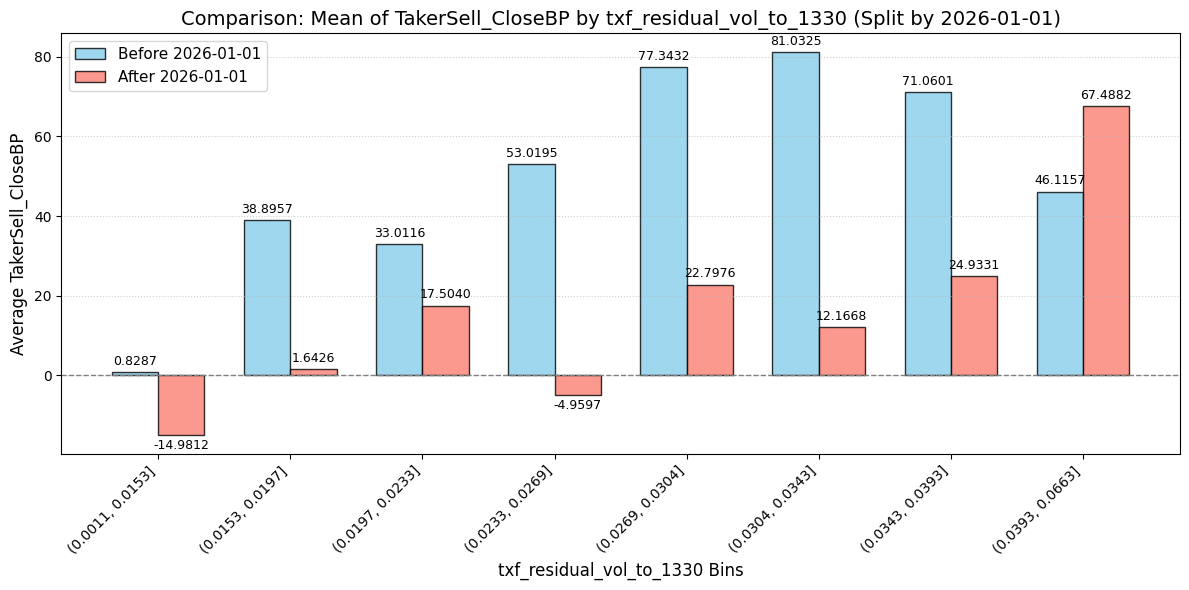

In [19]:
QcutAnalyzer.plot_qcut_analysis(signal_df[signal_df.isAbnormalDate == 0], 'txf_residual_vol_to_1330', 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01',  q= 8)

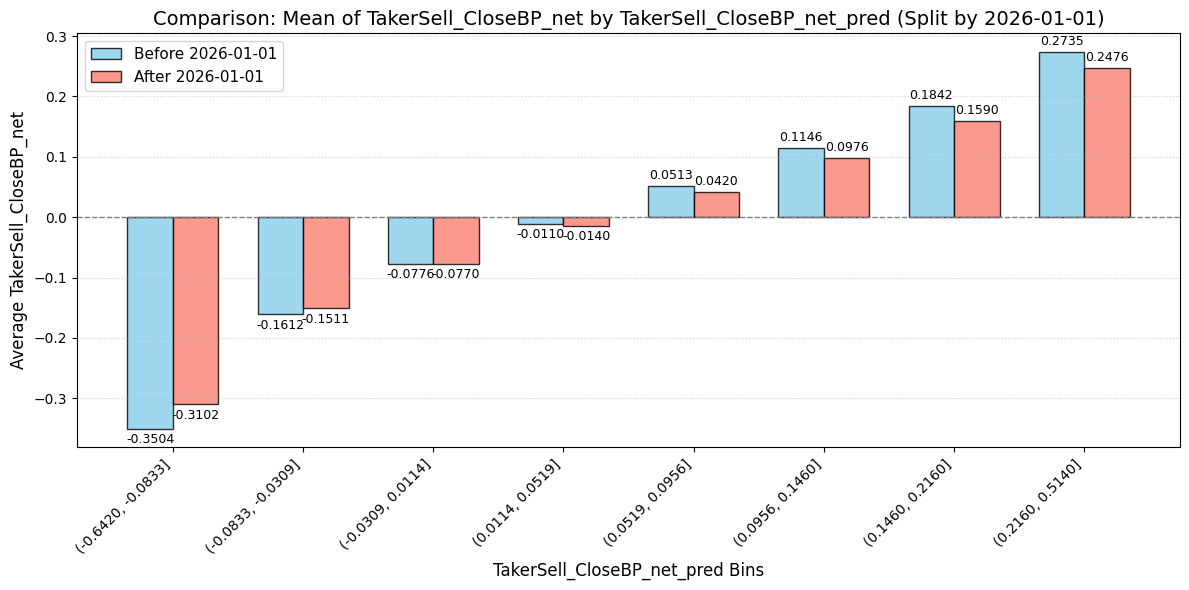

In [20]:
QcutAnalyzer.plot_qcut_analysis(signal_df[signal_df.isAbnormalDate == 0], 'TakerSell_CloseBP_net_pred', 'TakerSell_CloseBP_net', date_col='Date', split_date='2026-01-01',  q= 8)
# 對照用（含市場成分）：
# QcutAnalyzer.plot_qcut_analysis(signal_df[signal_df.isAbnormalDate == 0], 'TakerSell_CloseBP_net_pred', 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01',  q= 8)

In [21]:
# 每月 per-day Spearman IC：模型排序力的乾淨讀數（不受市場成分/跨日組成影響）
def _daily_ic(df, pred, label):
    return df.groupby('Date').apply(lambda p: p[pred].corr(p[label], method='spearman'))

_ic = pd.DataFrame({
    'net|net':   _daily_ic(signal_df, 'TakerSell_CloseBP_net_pred',  'TakerSell_CloseBP_net'),
    'net|raw':   _daily_ic(signal_df, 'TakerSell_CloseBP_net_pred',  'TakerSell_CloseBP'),
    'netM|netM': _daily_ic(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP_netM'),
    'netM|raw':  _daily_ic(signal_df, 'TakerSell_CloseBP_netM_pred', 'TakerSell_CloseBP'),
})
_ic.groupby(pd.to_datetime(_ic.index).strftime('%Y%m')).mean().round(4)

,net|net,net|raw,netM|netM,netM|raw
Date,,,,
202509,0.4392,0.2405,0.1897,0.1931
202510,0.5464,0.2238,0.2046,0.2079
202511,0.5366,0.2342,0.1773,0.1787
202512,0.5555,0.2192,0.1862,0.1841
202601,0.5698,0.0598,0.0518,0.0564
202602,0.5197,0.0072,0.0728,0.0327
202603,0.5226,0.0667,0.0552,0.0923
202604,0.5271,0.0679,0.0434,0.0435
202605,0.4822,0.0279,0.0016,0.0198


from matplotlib.pyplot import contour
from os import execve
for c in signal_df.columns :
    try :
        QcutAnalyzer.plot_qcut_analysis(signal_df_model[(signal_df_model.OTC !=1) ], c , 'TakerSell_CloseBP', date_col='Date', split_date='2026-01-01', q=8)
    except : 
        continue

In [22]:
import numpy as np
import pandas as pd


def prior_day_quantile(df, col, q=0.9, n_days=3, date_col="Date",
                       min_days=1, group=None):
    """每個交易日的門檻 = 前 n_days 個交易日該欄位的分位數（不含當日）。

    df       : DataFrame
    col      : 要取分位數的欄位（例如模型預測值）
    q        : 分位數，0.9 = 前 10%
    n_days   : 往前看幾個交易日
    min_days : 可用天數不足時回傳 NaN（該日不出訊號）
    group    : 選填，分組欄名（例如 'isAbnormalDate'），各組各自算門檻

    回傳與 df 對齊的 Series。當日資料完全不參與自己的門檻。
    """
    if group is not None:
        out = pd.Series(np.nan, index=df.index)
        for g, part in df.groupby(group, observed=True):
            out.loc[part.index] = prior_day_quantile(
                part, col, q=q, n_days=n_days, date_col=date_col,
                min_days=min_days)
        return out

    vals = (df.dropna(subset=[col])
              .groupby(date_col, observed=True)[col]
              .apply(lambda s: s.to_numpy()))
    dates = np.sort(vals.index.to_numpy())

    thr = {}
    for i, d in enumerate(dates):
        window = dates[max(0, i - n_days):i]          # 嚴格小於 d
        if len(window) < min_days:
            continue
        pool = np.concatenate([vals[w] for w in window])
        if pool.size:
            thr[d] = np.quantile(pool, q)
    return df[date_col].map(thr)


In [23]:
# 門檻於開盤前即全部固定：前 3 個交易日 pred 在同一 (時段×ToRef) 16-cell 內的分位數。
# 2D cell 讓訊號選單在時間與 ToRef 兩軸都貼齊母體分佈（對母體 TV 0.10→0.03、ToRef 3-5% 佔比 32%→26%=母體水位），
# holdout(2026-04~08) 1,111萬/Sharpe 2.22，較純時間桶 -2%。q=0.3/0.1 於 2025-12-05~2026-03-31 調參、之後驗證。
# 已驗證但未採用：改 label 扣條件基線 f̂（路線A）對組成無增量——預測『離散度』的時段梯度仍在，分桶門檻同時中和均值與離散度；
# 淺樹自動切桶（路線B）平衡度不如固定 16-cell。最終成交仍偏早盤是 accLots/Position 先到先贏的倉位上限造成，屬執行層，與訊號選擇無關。
condition = pd.Series( [True for i in range(len(signal_df))] )
signal_df['TimeBucket'] = pd.cut(signal_df.RemainSeconds, [3300, 6900, 10500, 14100, 99999], labels=False)
signal_df['ToRefBucket'] = pd.cut(signal_df.ToRef, [0, 0.01, 0.02, 0.03, 0.05], labels=False)
signal_df['Cell2D'] = signal_df['TimeBucket'] * 10 + signal_df['ToRefBucket']
signal_df['thr_net']  = prior_day_quantile(signal_df, 'TakerSell_CloseBP_net_pred',  q=0.3, n_days=3, group='Cell2D')
signal_df['thr_netM'] = prior_day_quantile(signal_df, 'TakerSell_CloseBP_netM_pred', q=0.1, n_days=3, group='Cell2D')

In [24]:

condition = condition & (
    (signal_df.TakerSell_CloseBP_net_pred  > signal_df.thr_net)
    & (signal_df.TakerSell_CloseBP_netM_pred > signal_df.thr_netM)
)

print( signal_df[condition].TakerSell_CloseBP.describe() )
print('')
print( 'cap BP : '+str( round(signal_df[condition].groupby(['Date','QuoteCode']).TakerSell_CloseBP.first().mean() ) ) )
print( 'averge prod num : '+str( round(signal_df[condition].groupby('Date').QuoteCode.nunique().mean(), 2)  ))

condition_recent = condition & (signal_df.Date > pd.to_datetime('2026-01-01')) # & (signal_df.Date.dt.strftime('%Y%m%d').astype(int) > 20260101) #& (signal_df.hft_participation > 0.3) & (signal_df.hft_sell_ToCloseBP > 0 )
print( signal_df[condition_recent].TakerSell_CloseBP.describe() ) 
print('')
print( 'cap BP : '+str( round(signal_df[condition_recent].groupby(['Date','QuoteCode']).TakerSell_CloseBP.first().mean() ) ) )
print( 'averge prod num : '+str( round(signal_df[condition_recent].groupby('Date').QuoteCode.nunique().mean(), 2)  ))

count    2.367807e+06
mean     3.684712e+01
std      3.553358e+02
min     -8.892893e+02
25%     -1.500000e+02
50%      5.117707e+01
75%      2.439024e+02
max      1.416490e+03
Name: TakerSell_CloseBP, dtype: float64

cap BP : 32
averge prod num : 98.55
count    1.808529e+06
mean     2.689580e+01
std      3.761482e+02
min     -8.892893e+02
25%     -1.929260e+02
50%      3.327787e+01
75%      2.517162e+02
max      1.416490e+03
Name: TakerSell_CloseBP, dtype: float64

cap BP : 20
averge prod num : 98.32


In [25]:
# signal_df_model = signal_df[ condition  ].sort_values(['Date','QuoteCode', 'TransTime']).reset_index(drop=True) #(signal_df.SpreadPairElapsed > 0.1)  &
signal_df_model = signal_df[ condition  & ((signal_df.OTC == 1) | (signal_df.MD_L1Rate_30_re > 0.25))& (signal_df.SpreadPairElapsed > 0.1) & (signal_df.ToRef > 0.0)  &((signal_df.AmountRank_canDayTrade<=100) |(signal_df.day_amount_rank <=100))  ].sort_values(['Date','QuoteCode', 'TransTime']).reset_index(drop=True) 
# 

ToRef
(0.000225, 0.00524]    34070
(0.00524, 0.0102]      41291
(0.0102, 0.0152]       30578
(0.0152, 0.0201]       31907
(0.0201, 0.0251]       22927
(0.0251, 0.0301]       22099
(0.0301, 0.035]        13896
(0.035, 0.04]          15655
(0.04, 0.045]          14997
(0.045, 0.05]          12825
Name: count, dtype: int64

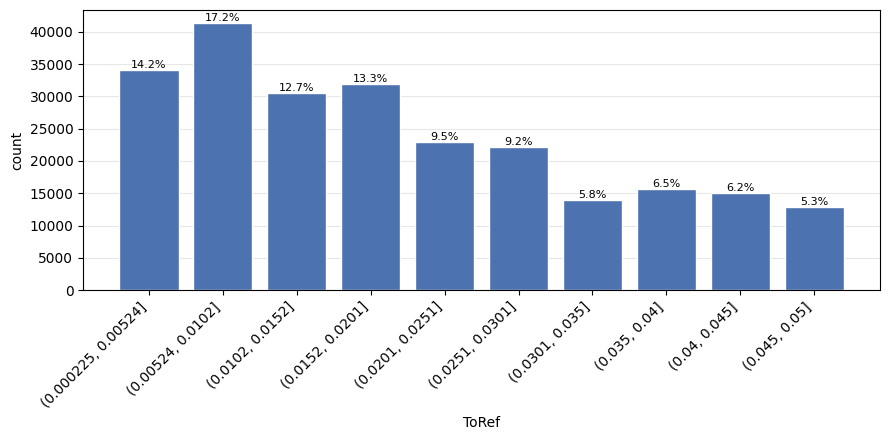

In [26]:
# QcutAnalyzer.plot_cut_distribution(signal_df_model, 'RemainSeconds', bins=10, annot='pct')
QcutAnalyzer.plot_cut_distribution(signal_df_model, 'ToRef', bins=10, annot='pct')

單檔最大 ：600


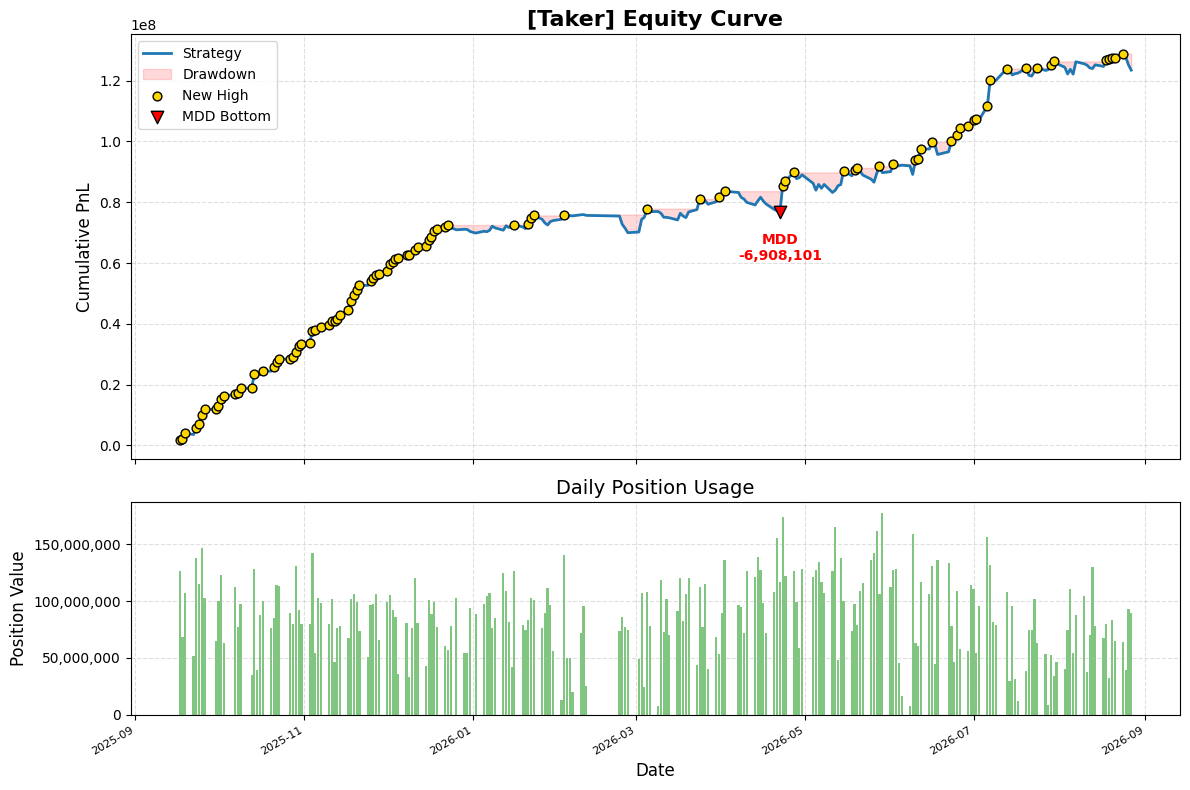


  回測模式: Taker
指標                 | 數值           

------------------ 基礎回報 ------------------
總報酬 (萬)           : 12,346.03
近一年報酬（萬）      : 12,346.03
風報比                  : 17.87
年化 Sharpe          : 5.11
創高最長費時 (天)     : 15
平均每日交易商品數   : 37.39

------------------ 勝率與效率 ------------------
年報酬率（基於平均部位）: 147.61%
近一年報酬率（近一年平均部位）: 140.22%
勝率 (日/單筆)      : 61.84% / 64.36%
平均BP (單筆/單位) : 63.04 / 61.5021

------------------ 風控與部位 ------------------
單日最大虧損（萬） : -323.27 萬
MDD金額/佔平均比   : -690.81 萬 / 7.85%
平均/最大部位(萬)  : 8,804.45 / 17,775.24
平均最大單一商品比  : 8.74%



In [27]:
signal_df_model['PosLots'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumcount') + 1
signal_df_model['Position'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumsum') / 10
signal_df_model['accLots'] = signal_df_model.groupby(['Date', 'QuoteCode']).BidPrice1.transform('cumcount') + 1
# for posLimit in [ 200, 250, 300, 400, 500, 750, 1000]:
for posLimit in [ 600 ]:
      signalwithRisk_df = signal_df_model[  
      (signal_df_model.accLots < signal_df_model.avg_askLots1 + signal_df_model.avg_bidLots1) &
      (signal_df_model.Position < posLimit)
      & (signal_df_model.BidPrice1<=3000) 
      & ( (signal_df_model.hft_strick_makerSpreadBP > -70) | (signal_df_model.hft_strick_makerSpreadBP.isna()))
      & ((signal_df_model.OTC ==1) | (signal_df_model.MD_L1Rate_30_re > 0.25))
            ].reset_index(drop=True)
      signalwithRisk_df['Date'] = signalwithRisk_df.Date.dt.strftime('%Y%m%d')
      
      print ("單檔最大 ：{}".format(posLimit))
      bt = BackTest(signalwithRisk_df)#[ (signalwithRisk_df.Date.astype(int) > 20260101 )])
      results = bt.run_analysis()
      daily_ticker_df = bt.get_daily_ticker_result()


In [28]:
signalwithRisk_df[ signalwithRisk_df.Date.astype(int) == signalwithRisk_df.Date.astype(int).max() ].QuoteCode.unique()

<ArrowStringArray>
['1303', '1802', '2327', '2426', '2484', '2634', '3131', '3163', '3211',
 '3260', '3293', '3324', '3363', '3374', '3441', '3450', '3532', '4908',
 '4979', '5425', '6187', '6209', '6239', '6274', '6278', '6488', '6830',
 '8021', '8033', '8150', '8299', '8358']
Length: 32, dtype: str

In [29]:
signalwithRisk_df[ (signalwithRisk_df.Date.astype(int) == signalwithRisk_df.Date.astype(int).max() ) & (signalwithRisk_df.FutureHigh >= signalwithRisk_df.RefPrice *1.08) ].QuoteCode.unique()

<ArrowStringArray>
['1303', '2634', '3211', '3363', '3374', '3441', '4908', '4979', '6187',
 '8033', '8358']
Length: 11, dtype: str

In [30]:
# 計算所有天數的排名比例
series1 = ( signalwithRisk_df.BidPrice1 * (signalwithRisk_df.TakerSell_CloseBP - 19.3) / 10000 / 10).groupby(signalwithRisk_df.Date).sum()
position = (signalwithRisk_df.BidPrice1 / 10).groupby(signalwithRisk_df.Date).sum()

rank_series = series1.rank(pct=True)

dateSeq = -1

# 取得最後一天的排名
latest_date = series1.index[dateSeq]
latest_rank = rank_series.iloc[dateSeq]

print(f"日期: {latest_date}")
print(f"單邊部位: {position.iloc[dateSeq]:.2f} 萬")
print(f"損益: {series1.iloc[dateSeq]:.2f} 萬")
print(f"損益: {series1.iloc[dateSeq]/position.iloc[dateSeq]*100 :.2f} % ")

rank_series = series1.rank()
latest_rank2 = rank_series.iloc[dateSeq]
print(f"排名: {latest_rank2},  {latest_rank :.2%}") # 例如 85.00%，代表贏過歷史 85% 的天數



日期: 20260827
單邊部位: 8989.75 萬
損益: -178.43 萬
損益: -1.98 % 
排名: 13.0,  5.70%


daily_ticker_df.groupby('Date').agg({'損益金額': 'sum', '損益率':'mean'}).reset_index(drop=False).to_csv('portfolios.csv')

# 1. 排序
signalwithRisk_df = signalwithRisk_df.sort_values(['Date', 'TransTime']).reset_index(drop=True)

# 2. 每日 cumsum b1 → 總部位
signalwithRisk_df['total_position'] = signalwithRisk_df.groupby('Date')['BidPrice1'].cumsum()

# 3. 當前應持有的避險口數
signalwithRisk_df['hedge_lots'] = signalwithRisk_df['total_position'] // 2_000

# 4. 新增口數 (每次跨越 100 萬邊界時 delta=±1)
signalwithRisk_df['delta_lots'] = signalwithRisk_df.groupby('Date')['hedge_lots'].diff().fillna(signalwithRisk_df['hedge_lots'])

# 5. 每口避險損益 = 進場(BidPrice2) → 收盤(CloseMean)
signalwithRisk_df['hedge_PL'] = (
    signalwithRisk_df['delta_lots'] 
    * (signalwithRisk_df['txf_CloseMean'] - (signalwithRisk_df['txf_BidPrice2'] + 4) ) / 100 * 50
).fillna(0)


daily_ticker_df = pd.merge(
    daily_ticker_df,
    signalwithRisk_df[['Date','QuoteCode','turnover_rate_rank', 'OTC']].assign(Date=lambda d: pd.to_datetime(d['Date'])),
    on=['Date','QuoteCode'],
    how='inner'
)

daily_ticker_df.to_csv('TradeRecord.csv',index=False)

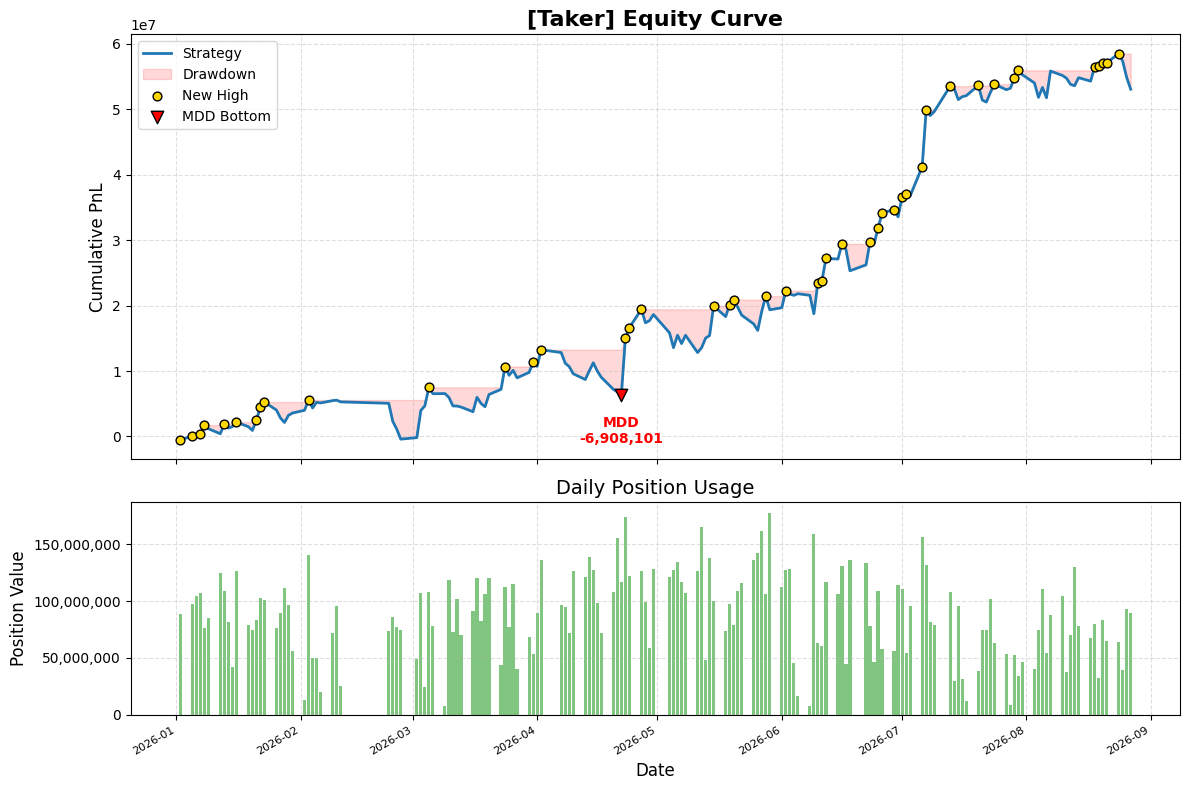


  回測模式: Taker
指標                 | 數值           

------------------ 基礎回報 ------------------
總報酬 (萬)           : 5,308.05
近一年報酬（萬）      : 5,308.05
風報比                  : 7.68
年化 Sharpe          : 2.86
創高最長費時 (天)     : 13
平均每日交易商品數   : 36.36

------------------ 勝率與效率 ------------------
年報酬率（基於平均部位）: 91.75%
近一年報酬率（近一年平均部位）: 60.02%
勝率 (日/單筆)      : 50.96% / 56.22%
平均BP (單筆/單位) : 40.28 / 38.2293

------------------ 風控與部位 ------------------
單日最大虧損（萬） : -323.27 萬
MDD金額/佔平均比   : -690.81 萬 / 7.81%
平均/最大部位(萬)  : 8,843.81 / 17,775.24
平均最大單一商品比  : 9.28%



In [31]:
bt = BackTest(signalwithRisk_df[ (signalwithRisk_df.Date.astype(int) > 20260101 )])
results = bt.run_analysis()
daily_ticker_df = bt.get_daily_ticker_result()

/home/kevin/Project/HFT/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Load daily benchmarks: 100%|██████████| 228/228 [01:00<00:00,  3.77it/s]

Valid strategy rows: 96,261 / 96,261 (100.00%)
TXF coverage: 100.00%
Rank-basket coverage: 100.00%
Rank-basket stop hits: 3,076 / 22,568 (13.63%)


,benchmark,latest_benchmark_rolling_bp,benchmark_direction,latest_alpha_rolling_bp,mean_alpha_net_bp,alpha_win_rate,observed_days
0,TXF open-close,57.361512,up,-165.23179,53.678347,0.592105,228
1,Top rank < 100 (stop-adjusted),89.872922,up,-197.74320,59.178724,0.557018,228


,Date,strategy_net_bp,txf_return_bp,rank_lt_100_stop_return_bp,alpha_vs_txf_net_bp,alpha_vs_top_net_bp
208,2026-07-31,-145.893927,256.164095,45.482438,-402.058022,-191.376365
209,2026-08-03,-309.197246,-0.346184,335.828021,-308.851062,-645.025268
210,2026-08-04,-295.480243,78.857729,356.723767,-374.337973,-652.204010
211,2026-08-05,136.978576,-31.128928,-26.309395,168.107504,163.287971
212,2026-08-06,-287.518187,12.428395,267.653696,-299.946583,-555.171883
213,2026-08-07,466.144330,-100.451922,-262.699562,566.596252,728.843892
214,2026-08-10,-64.496460,39.628497,175.313443,-104.124956,-239.809903
215,2026-08-11,-114.350705,40.438924,93.648174,-154.789628,-207.998879
216,2026-08-12,-131.893198,37.964067,197.336991,-169.857265,-329.230190
217,2026-08-13,-16.387285,-24.892314,20.976167,8.505029,-37.363452


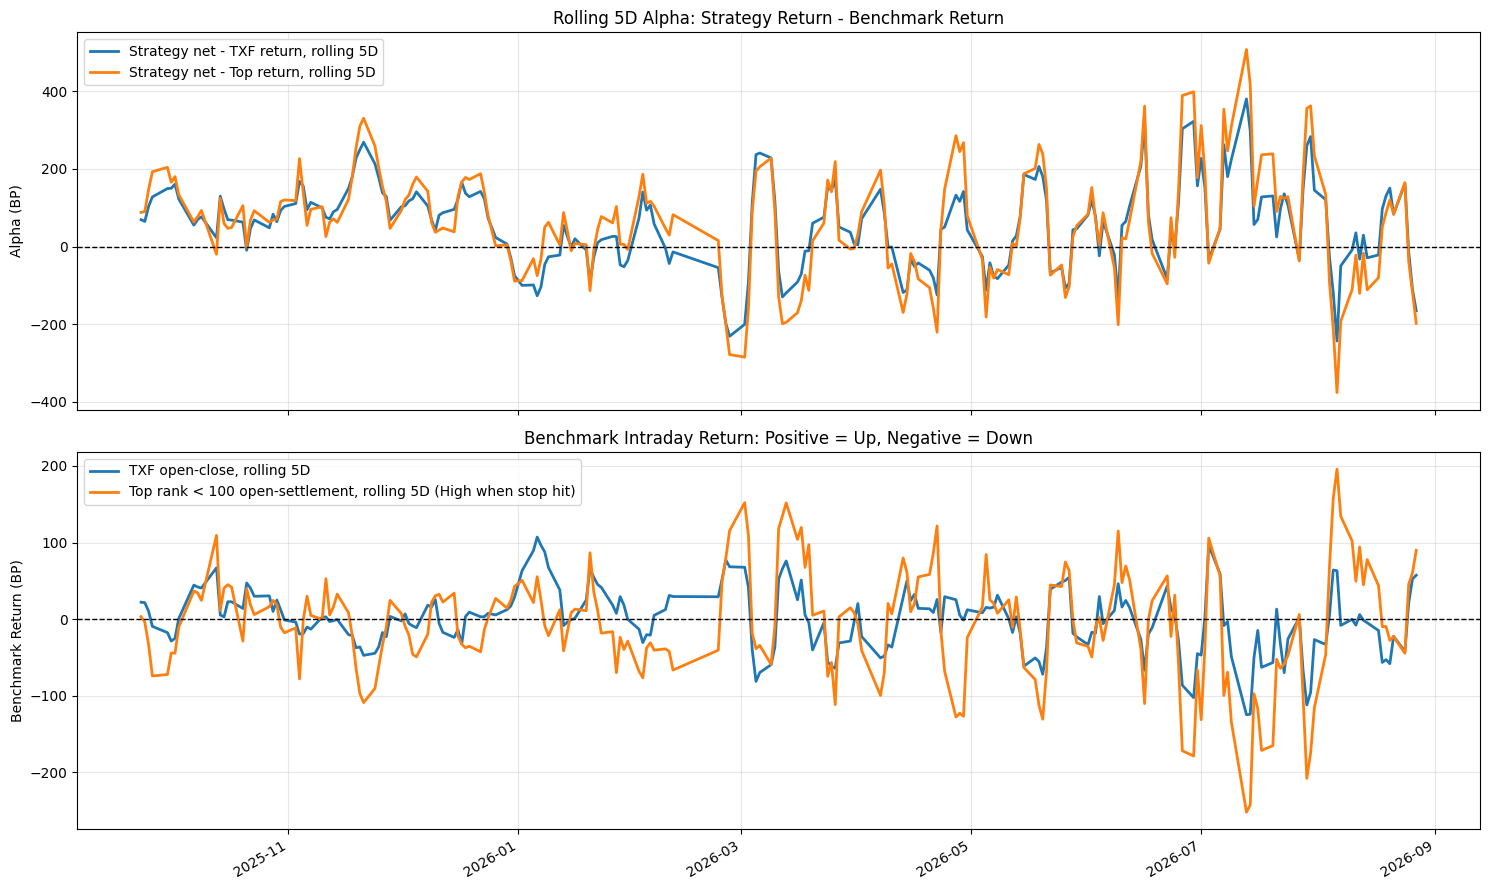

In [32]:
%run /tmp/refined_dual_beta.py

daily_compare, alpha_summary, fig = analyze_strategy_vs_benchmarks(
    signalwithRisk_df,
    project_root=Path("/home/kevin/Project/HFT"),
    rolling_days=5,
    top_stop_ratio=1.085,
)

display(alpha_summary)
display(
    daily_compare[
        [
            "Date",
            "strategy_net_bp",
            "txf_return_bp",
            "rank_lt_100_stop_return_bp",
            "alpha_vs_txf_net_bp",
            "alpha_vs_top_net_bp",
        ]
    ].tail(20)
)

plt.show()